# FCVG101 - Task 1B: Spatial Filtering, Frequency, Edges, Features

**Bài thực hành có thể chạy lại.** Nội dung mẫu sử dụng **ảnh tổng hợp** để kiểm tra mã, không phải dữ liệu thực nghiệm của một camera hay bộ dữ liệu ngoài. Thay bằng ảnh được phép sử dụng để làm Coursework.

Các phần: (1) Noise + Box/Gaussian/Median + MSE; (2) FFT + masks + inverse FFT; (3) Sobel/Canny; (4) Harris/SIFT/Ratio Test và RANSAC nâng cao.

**Khởi chạy Jupyter từ thư mục dự án**, nơi có `demo_task1b.py`, `src/`, `data/` để các lệnh dưới đây chạy đúng.

## Cell 1 – Chuẩn bị môi trường

Nếu thiếu thư viện, chạy một cell riêng: `%pip install -r requirements.txt`. Sau khi cài, restart kernel nếu cần.

In [22]:
from pathlib import Path
import sys
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'src' / 'classical_cv.py').exists():
    # Jupyter may start in the notebooks/ subfolder
    if (ROOT.parent / 'src' / 'classical_cv.py').exists():
        ROOT = ROOT.parent
    else:
        raise FileNotFoundError('Mở Jupyter từ thư mục dự án chứa src/ và demo_task1b.py')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.classical_cv import *
print('Project:', ROOT)
print('OpenCV:', cv2.__version__)

Project: d:\School\fcvg101\materials\FCVG101_Task1B_BoMaNguon_Notebook\FCVG101_Task1B_Project
OpenCV: 5.0.0


## Cell 2 – Tạo dữ liệu kiểm thử (tổng hợp)

Ảnh minh họa tự tạo gồm vùng sáng, cạnh, chữ và họa tiết để kiểm tra thuật toán. `same_scene` là ảnh đã xoay + thay đổi tỷ lệ; `unrelated` là ảnh không cùng cảnh.

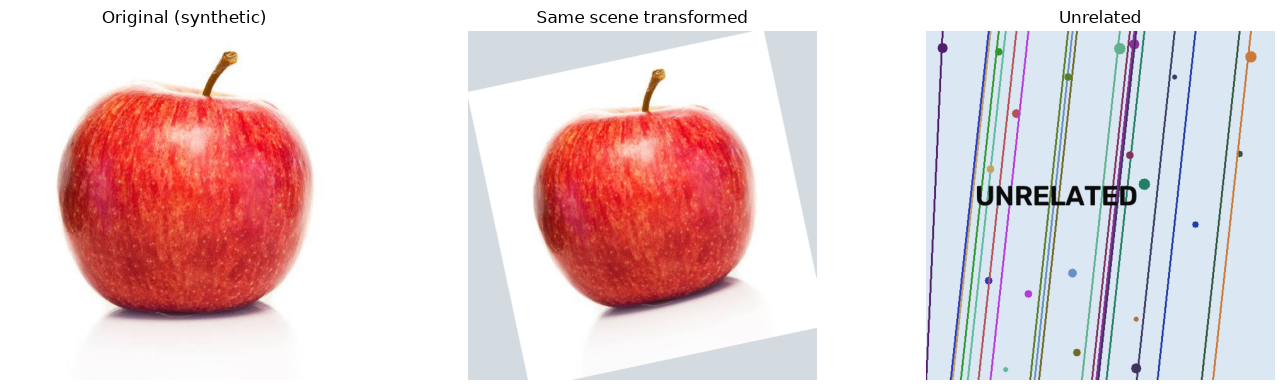

In [23]:
base = load_bgr(ROOT / 'data' / 'my_image.jpg')
same_scene = make_same_scene_variant(base)
unrelated = make_unrelated_scene(*base.shape[:2])

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, title, im in zip(axs, ['Original (synthetic)', 'Same scene transformed', 'Unrelated'], [base, same_scene, unrelated]):
    ax.imshow(bgr_to_rgb(im)); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()


## Cell 3 – Spatial filtering: tạo hai loại nhiễu

Gaussian noise (σ=20) là nhiễu cộng tính liên tục. Salt-and-pepper 5% làm một phần pixel thành đen/trắng cực trị. Seed cố định để lặp lại thí nghiệm.

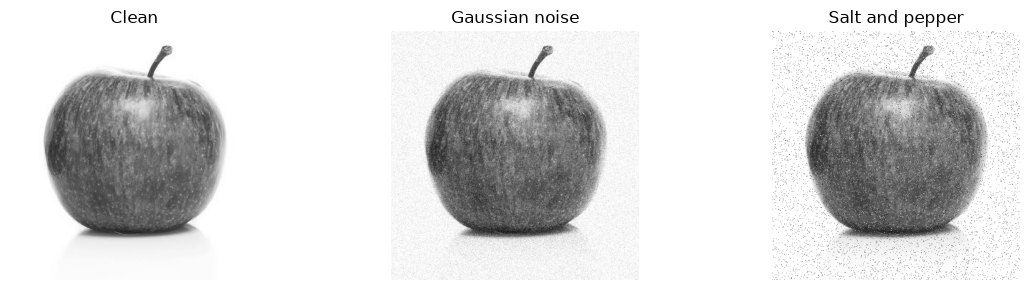

In [24]:
clean = to_gray(base)
noise_g = add_gaussian_noise(clean, sigma=20, seed=42)
noise_sp = add_salt_pepper_noise(clean, proportion=0.05, seed=43)
fig, axs = plt.subplots(1,3,figsize=(12,3))
for ax, name, img in zip(axs,['Clean','Gaussian noise','Salt and pepper'],[clean,noise_g,noise_sp]):
    ax.imshow(img,cmap='gray',vmin=0,vmax=255);ax.set_title(name);ax.axis('off')
plt.tight_layout();plt.show()

## Cell 4 – So sánh Box, Gaussian, Median

Chạy từng loại noise qua 3 filters. `MSE` thấp hơn và `PSNR` cao hơn là tốt hơn **khi so với chính ảnh sạch tương ứng**. Làm mượt có thể làm sai các cạnh sắc, nên Gaussian **không bảo đảm** luôn đạt MSE tốt nhất.

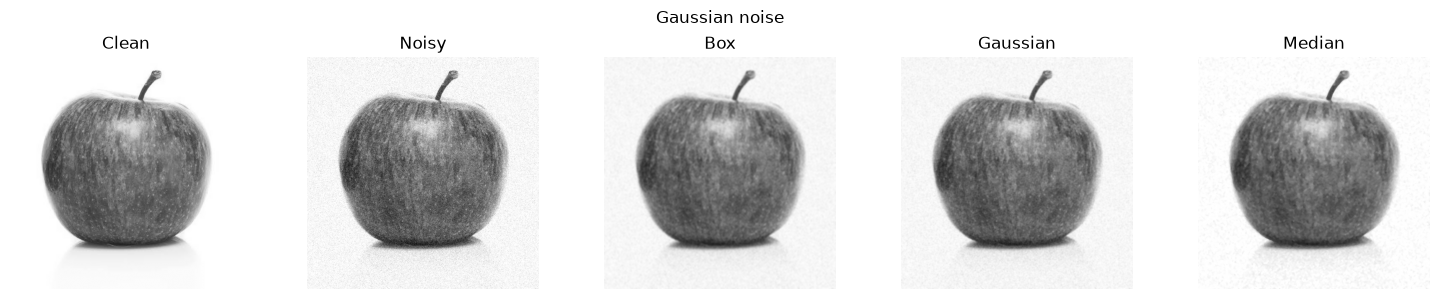

Gaussian noise | Noisy | MSE: 292.21 | PSNR: 23.47 dB
Gaussian noise | Box | MSE: 78.14 | PSNR: 29.2 dB
Gaussian noise | Gaussian | MSE: 70.62 | PSNR: 29.64 dB
Gaussian noise | Median | MSE: 50.98 | PSNR: 31.06 dB


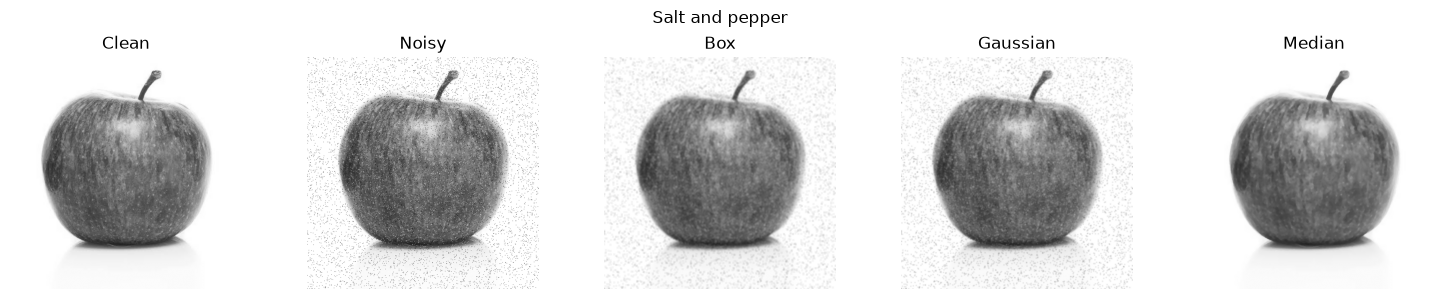

Salt and pepper | Noisy | MSE: 1313.93 | PSNR: 16.95 dB
Salt and pepper | Box | MSE: 109.91 | PSNR: 27.72 dB
Salt and pepper | Gaussian | MSE: 126.56 | PSNR: 27.11 dB
Salt and pepper | Median | MSE: 28.7 | PSNR: 33.55 dB


In [25]:
for label, noisy in [('Gaussian noise',noise_g),('Salt and pepper',noise_sp)]:
    outs=filtering_outputs(noisy,kernel=5,sigma=1.2)
    fig,axs=plt.subplots(1,5,figsize=(15,3))
    items=[('Clean',clean),('Noisy',noisy),*outs.items()]
    for ax,(title,im) in zip(axs,items):
        ax.imshow(im,cmap='gray',vmin=0,vmax=255);ax.set_title(title);ax.axis('off')
    plt.suptitle(label);plt.tight_layout();plt.show()
    for method,im in [('Noisy',noisy),*outs.items()]:
        print(label, '|',method,'| MSE:',round(mse(clean,im),2),'| PSNR:',round(psnr(clean,im),2),'dB')


## Cell 5 – Frequency domain filtering (FFT)

FFT chuyển ảnh sang phổ tần số. Sau `fftshift`, tần số thấp ở giữa. `ideal_low_mask` giữ vùng tâm; `ideal_high_mask` giữ ngoài tâm. Dùng `ifftshift` + `ifft2` trở lại ảnh. Ảnh high-pass **có thể mang số âm**, nên hiển thị thang đối xứng để hiểu dấu.

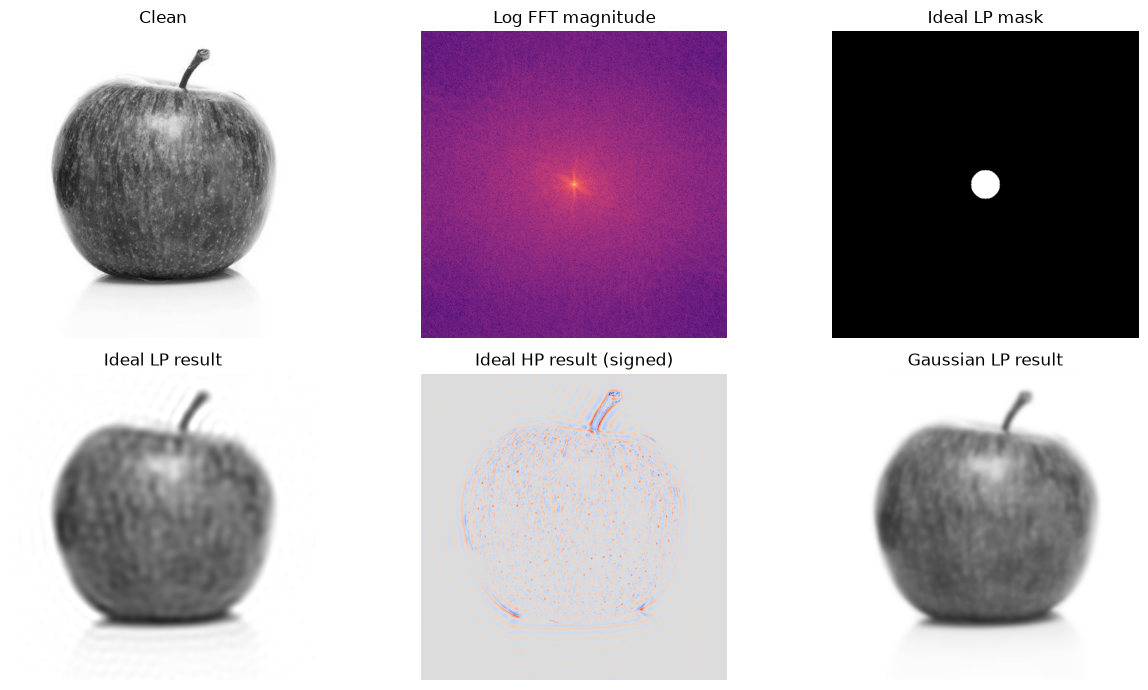

In [16]:
freq=frequency_outputs(clean,cutoff=26,gauss_sigma=25)
fig, axs=plt.subplots(2,3,figsize=(13,7))
items=[('Clean',clean,'gray',None),('Log FFT magnitude',freq['spectrum_log'],'magma',None),
       ('Ideal LP mask',freq['ideal_low_mask'],'gray',None),
       ('Ideal LP result',freq['ideal_low_img'],'gray',(0,255)),
       ('Ideal HP result (signed)',freq['ideal_high_img'],'coolwarm',(-100,100)),
       ('Gaussian LP result',freq['gaussian_low_img'],'gray',(0,255))]
for ax,(title,im,cmap,lims) in zip(axs.flat,items):
    opts={'cmap':cmap}
    if lims:opts.update(vmin=lims[0],vmax=lims[1])
    ax.imshow(im,**opts);ax.set_title(title);ax.axis('off')
plt.tight_layout();plt.show()


## Cell 6 – Sobel và Canny

`Gx`: thay đổi độ sáng theo chiều ngang (làm nổi cạnh đứng). `Gy`: thay đổi theo chiều dọc (làm nổi cạnh ngang). `magnitude = sqrt(Gx²+Gy²)`; Canny tạo bản đồ cạnh mảnh nhờ các bước xử lý bổ sung.

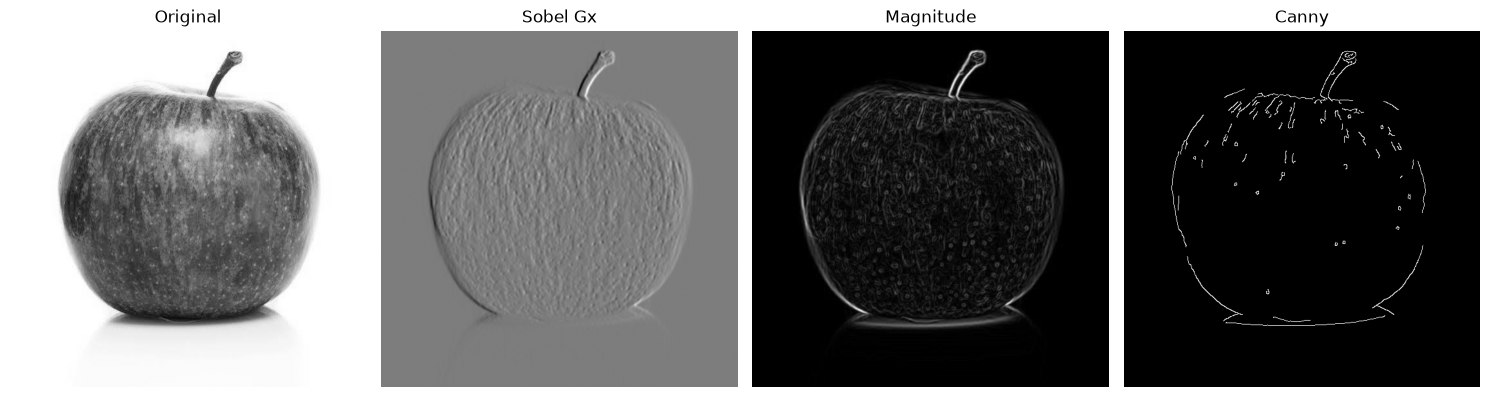

Canny edge pixel fraction: 0.009


In [17]:
e=edges_outputs(clean,low=80,high=160)
fig,axs=plt.subplots(1,4,figsize=(15,4))
for ax,(name,im) in zip(axs,[('Original',clean),('Sobel Gx',e['gx']),('Magnitude',e['magnitude']),('Canny',e['canny'])]):
    ax.imshow(im,cmap='gray');ax.set_title(name);ax.axis('off')
plt.tight_layout();plt.show()
print('Canny edge pixel fraction:',round(float((e['canny']>0).mean()),4))

## Cell 7 – Interest Points: Harris

Harris tìm góc: cả hai hướng biến đổi sáng đều mạnh. `harris_points` thực hiện non-maximum selection để tránh hiển thị quá nhiều pixel liền nhau.

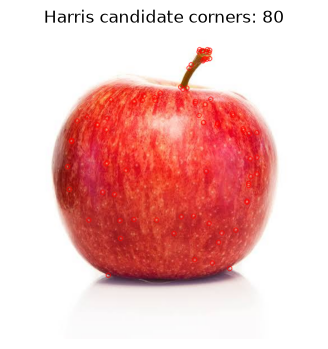

In [18]:
response, corners=harris_points(clean,max_points=80)
plt.figure(figsize=(7,4))
plt.imshow(bgr_to_rgb(draw_harris(base,corners)))
plt.title(f'Harris candidate corners: {len(corners)}')
plt.axis('off');plt.show()

## Cell 8 – SIFT và Lowe's Ratio Test

SIFT tạo mô tả đặc trưng bất biến tương đối với scale/rotation. Với mỗi descriptor của ảnh 1, tìm hai ứng viên ảnh 2 và giữ khi `d_best < 0.75*d_second`. Hàm trả về **cv2.DMatch** (không phải tuple) để vẽ được bằng `cv2.drawMatches`.

Keypoints: 943 680 286
Good matches - same / unrelated: 489 4


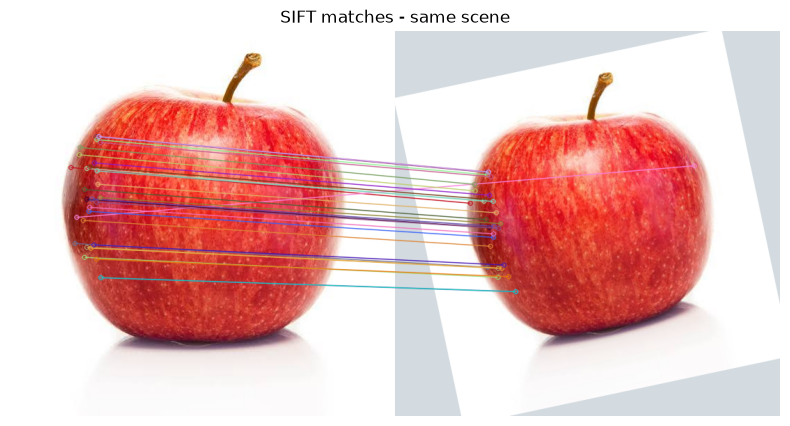

In [19]:
kp1,kp2,good_same=sift_match(base,same_scene,ratio=0.75)
_,kp3,good_other=sift_match(base,unrelated,ratio=0.75)
print('Keypoints:',len(kp1),len(kp2),len(kp3))
print('Good matches - same / unrelated:',len(good_same),len(good_other))
vis=cv2.drawMatches(base,kp1,same_scene,kp2,good_same[:30],None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(14,5));plt.imshow(bgr_to_rgb(vis))
plt.axis('off');plt.title('SIFT matches - same scene');plt.show()

## Cell 9 – Kiểm tra hình học bằng RANSAC (mở rộng)

Lowe Ratio Test loại match mơ hồ; chưa bảo đảm tất cả match đúng về hình học. `findHomography(..., RANSAC, ...)` chỉ phù hợp khi quan hệ ảnh được xấp xỉ bằng homography (ví dụ cùng mặt phẳng / phép quay camera).

In [20]:
H, inliers=homography_inliers(kp1,kp2,good_same)
print('Good matches:',len(good_same))
print('Geometric inliers:',inliers)
print('Inlier proportion:',round(inliers/max(len(good_same),1),3))

Good matches: 489
Geometric inliers: 485
Inlier proportion: 0.992


## Cell 10 – Lưu toàn bộ hình và bảng số liệu phục vụ báo cáo

Mã nguồn chính `demo_task1b.py` sẽ tạo `results/01_filter_comparison.png` ... `05_sift_matches.png` và `metrics_filtering.csv`/`metrics_summary.json`.

In [21]:
import subprocess
result=subprocess.run([sys.executable, str(ROOT/'demo_task1b.py')], cwd=ROOT, capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    raise RuntimeError(result.stderr)
print('Saved:',list(sorted(p.name for p in (ROOT/'results').iterdir())))

{
  "type": "SYNTHETIC DEMO; replace with own data for coursework",
  "image_size": [
    480,
    320
  ],
  "harris_candidates": 80,
  "sift_kp_original": 252,
  "sift_kp_transformed": 331,
  "sift_kp_unrelated": 298,
  "good_matches_same": 140,
  "good_matches_unrelated": 19,
  "ransac_inliers_same": 126
}
Saved figures and metrics to: D:\School\fcvg101\materials\FCVG101_Task1B_BoMaNguon_Notebook\FCVG101_Task1B_Project\results

Saved: ['01_filter_comparison.png', '02_frequency_domain.png', '03_edges.png', '04_harris.png', '05_sift_matches.png', 'metrics_filtering.csv', 'metrics_summary.json']


## Bài tập tự thực hiện với dữ liệu thật

1. Thay `base` bằng ảnh của dự án: `base = load_bgr(ROOT / 'data' / 'my_image.jpg')`.
2. Lặp lại Noise/Filtering và ghi MSE/PSNR (so với ảnh clean trước khi tạo noise).
3. Với FFT, thử cutoff=15/26/40, quan sát mức blur và ringing.
4. Với Canny, thử (40,100), (80,160), (120,240); nhận xét edge density và false edges.
5. Với SIFT, thay `same_scene` bằng một ảnh thật khác của **cùng cảnh**, và thêm một ảnh unrelated thực tế. Chú ý nguồn dữ liệu, độ phủ chồng lấp, điều kiện ánh sáng.
6. Viết nhận xét riêng từ số liệu tự chạy, không ghi số demo vào báo cáo Coursework như số thực nghiệm.

**Câu hỏi kiểm tra:** Vì sao Gaussian filtering đôi khi có MSE cao hơn ảnh nhiễu? Phổ sau fftshift có vùng DC ở đâu? Tại sao Sobel Gx làm rõ cạnh đứng? Lowe Ratio Test loại loại match nào?